# VLA-JEPA: a language-conditioned policy with a latent world model

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/vlajepa.ipynb)

[VLA-JEPA](https://arxiv.org/abs/2602.10098) ([code](https://github.com/ginwind/VLA-JEPA)) trains a vision-language-action policy together with a JEPA world model. A VLM reads the current image and the instruction, and writes latent-action tokens and embodied-action tokens. The latent-action tokens condition a predictor of future states. A frozen V-JEPA 2 encoder supplies those states as targets, and they never reach the VLM. The embodied-action tokens condition a flow-matching action expert.

Here the agent is a point in Two-Rooms, and the instructions name a region, such as "go to the top left of the right room". The training data is random play with no instructions. Each clip gets as its instruction the region the agent reached later in the episode (a hindsight label).

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]" timm einops

In [2]:
import torch

from torch_world import evaluation, metrics, plots
from torch_world.envs import TwoRooms
from torch_world.models import VLAJEPA
from torch_world.nn import VideoTokens, VisionTransformer, WordTokenizer
from torch_world.planning import RecedingHorizon
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_float32_matmul_precision("high")  # TF32 matmuls on recent GPUs
FRAMES, CHUNK = 8, 7  # world states per clip and actions per chunk, as in the paper

## Instructions
Each room splits into four regions, which gives eight instructions. `region` maps a position to the instruction that names where it is.

In [3]:
SIDES, ROWS = ["left", "right"], ["top", "bottom"]
INSTRUCTIONS = [f"go to the {r} {s} of the {room} room" for room in SIDES for r in ROWS for s in SIDES]
tokenizer = WordTokenizer(INSTRUCTIONS, device=device)
ids, mask = tokenizer(INSTRUCTIONS)  # (8, 9) word ids, one row per instruction


def region(states):
    """Index into INSTRUCTIONS of positions (..., 2): room, then top/bottom, then left/right of the room's center."""
    x, y = states[..., 0], states[..., 1]
    room = (x > 0.5).long()
    return 4 * room + 2 * (y > 0.5).long() + (x > 0.25 + 0.5 * room).long()


CENTERS = torch.tensor([[0.25 + 0.5 * room + (0.11 if s else -0.11), 0.72 if r else 0.28] for room in (0, 1) for r in (0, 1) for s in (0, 1)], device=device)
assert (region(CENTERS) == torch.arange(8, device=device)).all()
print("\n".join(INSTRUCTIONS))

go to the top left of the left room
go to the top right of the left room
go to the bottom left of the left room
go to the bottom right of the left room
go to the top left of the right room
go to the top right of the right room
go to the bottom left of the right room
go to the bottom right of the right room


## Data and model
1,500 episodes of 64 random steps (each action repeats with probability 0.8, so some episodes cross the door). The frozen target encoder is the released V-JEPA 2.1 ViT-B, which turns each 64×64 frame into 16 tokens. The world states are computed once.

In [4]:
EPISODES, LENGTH = 1500, 64
data = TwoRooms(batch_size=EPISODES, device=device).collect(LENGTH, generator=torch.Generator().manual_seed(0))
images = (data.pop("pixels") * 255).round().to(torch.uint8)  # (E, T, 3, 64, 64)
target = VideoTokens.from_hub("vjepa2_1_vit_base_384", size=64).to(device)


@torch.no_grad()
def world_states(images):
    """Frozen V-JEPA 2.1 tokens (E, T, 16, 768) of uint8 frames (E, T, 3, 64, 64), kept in half precision."""
    flat = images.flatten(0, 1)
    return torch.cat([target(x).half() for x in flat.split(2048)]).unflatten(0, images.shape[:2])


latents = world_states(images)
print(tuple(latents.shape))

/clusterhome/kleyton/pytorch-world-p2-20261025/pydeps/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


(1500, 64, 16, 768)


In [5]:
class Hindsight:
    """Random clips of FRAMES world states and the CHUNK actions from their first frame, each labeled with the
    instruction naming the region the agent is in some CHUNK to 40 steps later."""

    def __init__(self, data, images, latents, steps, batch_size=256):
        self.data, self.images, self.latents, self.steps, self.batch_size = data, images, latents, steps, batch_size

    def __iter__(self):
        E, T = self.images.shape[:2]
        for _ in range(self.steps):
            e = torch.randint(E, (self.batch_size,), device=device)
            t = torch.randint(T - FRAMES + 1, (self.batch_size,), device=device)
            later = t + CHUNK + (torch.rand(self.batch_size, device=device) * ((t + 40).clamp(max=T - 1) - t - CHUNK + 1)).long()
            label = region(self.data["states"][e, later])
            clip = t[:, None] + torch.arange(FRAMES, device=device)
            yield {
                "pixels": self.images[e, t][:, None].float() / 255,
                "latents": self.latents[e[:, None], clip],
                "actions": self.data["actions"][e[:, None], clip[:, :CHUNK]],
                "ids": ids[label],
                "mask": mask[label],
                "label": label,
            }


def make(wm_weight=0.1):
    vision = VisionTransformer(img_size=64, patch_size=8, embed_dim=192, depth=4, num_heads=4)  # the VLM's vision tower
    return VLAJEPA(
        vision, target, len(tokenizer), action_dim=2, vision_dim=192, target_dim=768, num_patches=16, frames=FRAMES,
        chunk_size=CHUNK, dim=192, depth=4, num_heads=4, predictor_dim=256, predictor_depth=4, predictor_heads=8,
        expert_dim=256, expert_depth=4, expert_heads=8, wm_weight=wm_weight,
    ).to(device)


model = make()
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.1f}M trainable parameters")

12.2M trainable parameters


## Train
The loss is flow matching on the action chunk plus 0.1 times the L1 world-model loss, end to end through the VLM. The target encoder stays frozen. For the ablation, an identical model trains with the world-model weight set to 0, so it is a plain VLA with a flow-matching head.

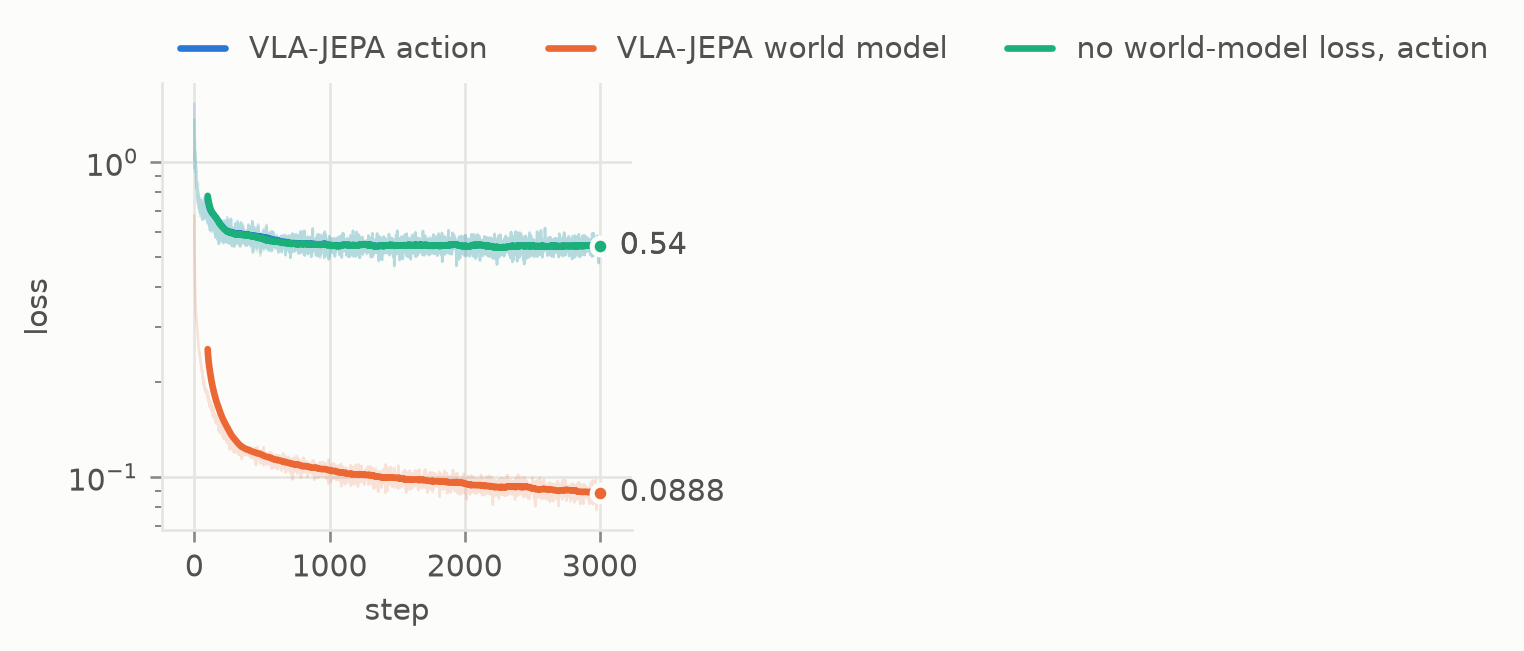

In [6]:
STEPS, EPOCHS = 500, 6  # 3,000 steps of 128 clips per model
loader = Hindsight(data, images, latents, STEPS, batch_size=128)
inputs = lambda b: (b["pixels"], b["ids"], b["mask"], b["actions"], None, b["latents"])
log = fit(model, loader, epochs=EPOCHS, lr=3e-4, clip=1.0, inputs=inputs)

torch.manual_seed(0)
ablation = make(wm_weight=0.0)
ablation_log = fit(ablation, loader, epochs=EPOCHS, lr=3e-4, clip=1.0, inputs=inputs)
plots.curves({"VLA-JEPA action": log["action"], "VLA-JEPA world model": log["wm"], "no world-model loss, action": ablation_log["action"]}, smooth=100)

## What the latent world model imagines
On new episodes, the VLM reads the first frame and the clip's hindsight instruction. The predictor then unrolls its latent-action tokens from the true first state for seven steps (`imagine`), and we measure the L1 distance to the true V-JEPA states. Two references: copying the first state, and the same unroll under a wrong instruction. If the wrong instruction gives a worse prediction, the latent-action tokens carry what the instruction says about the future.

/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


hindsight instruction   0.097 0.114 0.128 0.140 0.149 0.158 0.162
wrong instruction       0.098 0.115 0.130 0.142 0.151 0.161 0.165
copy the first state    0.096 0.122 0.138 0.151 0.162 0.172 0.177


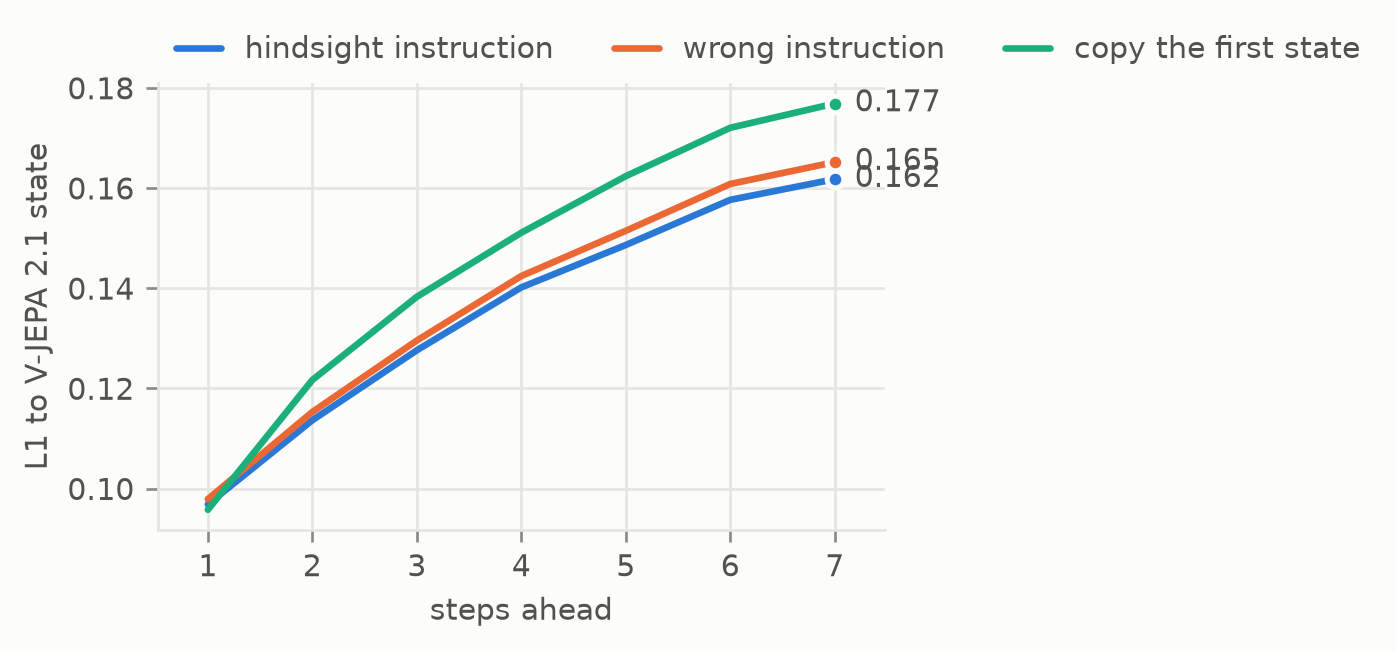

In [7]:
test = TwoRooms(batch_size=256, device=device).collect(LENGTH, generator=torch.Generator().manual_seed(1))
test_images = (test.pop("pixels") * 255).round().to(torch.uint8)
test_latents = world_states(test_images)
batch = next(iter(Hindsight(test, test_images, test_latents, steps=1, batch_size=1024)))
true = batch["latents"].float()
wrong = (batch["label"] + torch.randint(1, 8, batch["label"].shape, device=device)) % 8
with torch.no_grad():
    errors = {}
    for name, label in {"hindsight instruction": batch["label"], "wrong instruction": wrong}.items():
        latent, _ = model.context(batch["pixels"][:, 0], ids[label], mask[label])
        errors[name] = (model.rollout(true[:, :1], latent) - true).abs().mean((0, 2, 3))[1:].tolist()
    errors["copy the first state"] = (true[:, :1] - true).abs().mean((0, 2, 3))[1:].tolist()
for name, e in errors.items():
    print(f"{name:24s}" + " ".join(f"{v:.3f}" for v in e))
plots.curves({k: (range(1, FRAMES), v) for k, v in errors.items()}, smooth=1, logy=False, xlabel="steps ahead", ylabel="L1 to V-JEPA 2.1 state")

## Follow instructions
256 episodes of 60 steps. Each starts at a random free position, with an instruction naming one of the seven regions the agent is not in (about four in seven lie in the other room, behind the wall). The policies execute four actions of each sampled chunk and then sample again. An episode succeeds if the agent enters the named region. The same policy run with a wrong instruction is a control: its success is still measured against the true one, so it shows how much of the success comes from the instruction.

In [8]:
N, HORIZON = 256, 60
env = TwoRooms(batch_size=N, device=device)
g = torch.Generator().manual_seed(2)
start = env.free(N, generator=g)
task = (region(start) + torch.randint(1, 8, (N,), generator=g).to(device)) % 8
decoy = (task + torch.randint(1, 8, (N,), generator=g).to(device)) % 8
other_room = task // 4 != region(start) // 4


def follow(model, task, execute=4):
    """Closed-loop policy: sample an action chunk for each observation and instruction, run `execute` of it."""
    return RecedingHorizon(lambda obs: model.sample_actions(obs.to(device), ids[task], mask[task]), action_dim=2, execute=execute)


policies = {
    "VLA-JEPA": follow(model, task),
    "no world-model loss": follow(ablation, task),
    "VLA-JEPA, wrong instruction": follow(model, decoy),
    "random actions": evaluation.random_policy(env),
}
result = evaluation.goal_reaching(env, policies, start, CENTERS[task], steps=HORIZON)
entered = {name: (region(path[:, 1:]) == task[:, None]).any(1) for name, path in result.paths.items()}
groups = {
    "all tasks": {k: metrics.success_rate(s) for k, s in entered.items()},
    "same room": {k: metrics.success_rate(s[~other_room]) for k, s in entered.items()},
    "other room": {k: metrics.success_rate(s[other_room]) for k, s in entered.items()},
}
for row, rates in groups.items():
    print(row, f"({rates['random actions'].n} episodes)")
    for name, rate in rates.items():
        print(f"  {name:30s} {rate}")

all tasks (256 episodes)
  VLA-JEPA                       47% [41%, 53%]
  no world-model loss            49% [43%, 55%]
  VLA-JEPA, wrong instruction    22% [17%, 27%]
  random actions                 32% [27%, 38%]
same room (112 episodes)
  VLA-JEPA                       96% [90%, 98%]
  no world-model loss            98% [94%, 100%]
  VLA-JEPA, wrong instruction    39% [31%, 49%]
  random actions                 62% [52%, 70%]
other room (144 episodes)
  VLA-JEPA                       9% [5%, 15%]
  no world-model loss            10% [6%, 16%]
  VLA-JEPA, wrong instruction    8% [5%, 14%]
  random actions                 10% [6%, 16%]


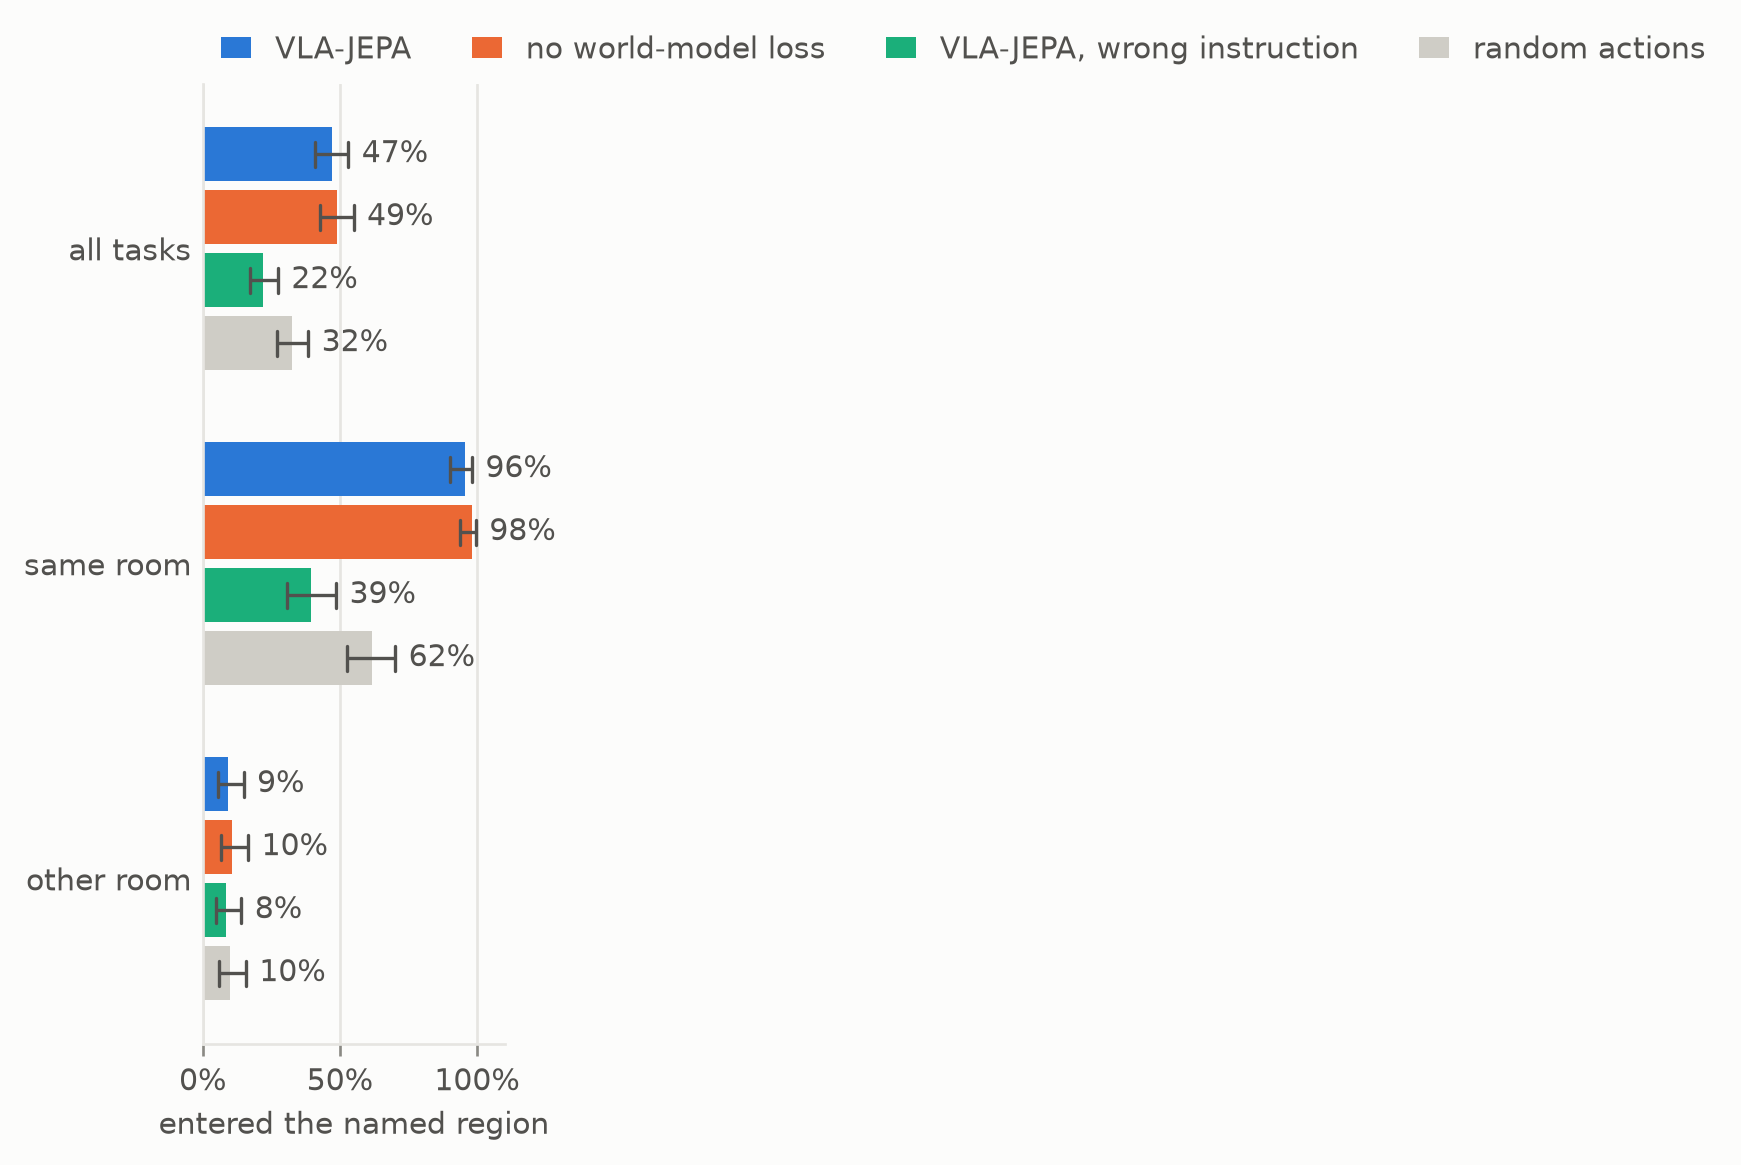

In [9]:
plots.bars(groups, xlabel="entered the named region", baseline="random actions")

## One start, eight instructions
The same start position and all eight instructions. Each star marks the center of the named region, and ✓ means the agent entered that region.

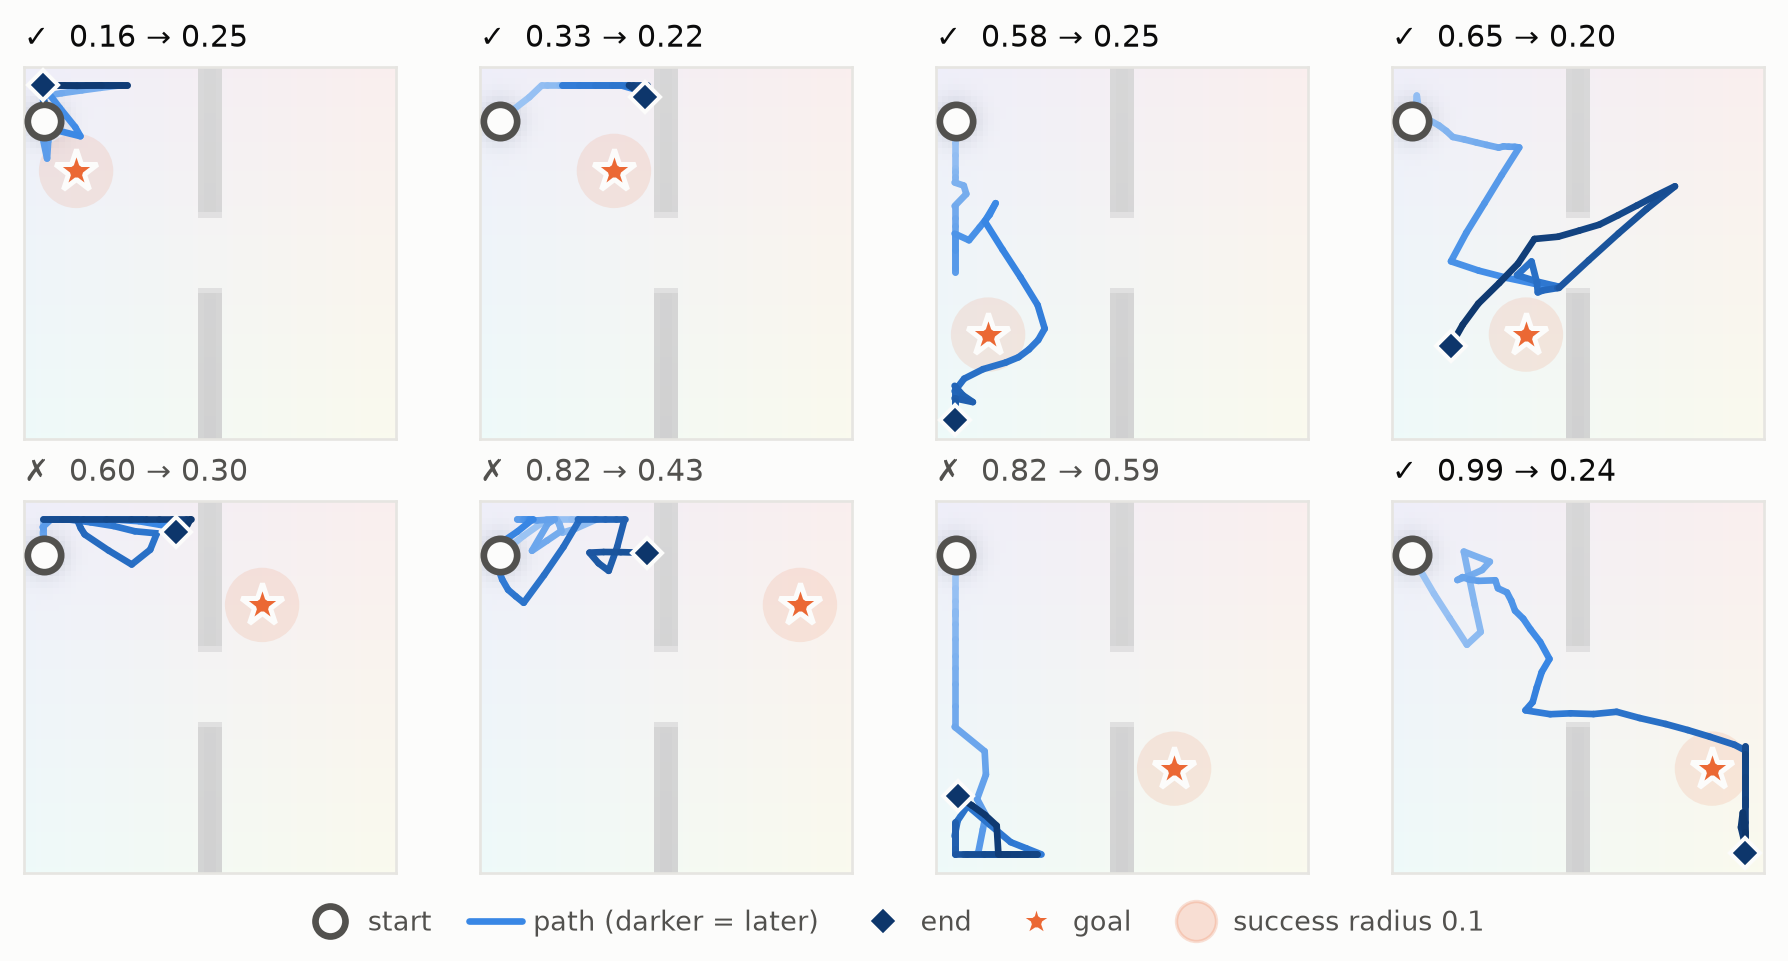

In [10]:
one = TwoRooms(batch_size=8, device=device)
start8, task8 = env.free(1, generator=torch.Generator().manual_seed(3)).repeat(8, 1), torch.arange(8, device=device)
paths = evaluation.goal_reaching(one, {"VLA-JEPA": follow(model, task8)}, start8, CENTERS, steps=HORIZON).paths["VLA-JEPA"]
plots.trajectories(paths, CENTERS, radius=0.1, background=one.render(start8), success=(region(paths[:, 1:]) == task8[:, None]).any(1))

## Summary
When the named region is in the agent's own room, VLA-JEPA enters it in 96% [90%, 98%] of 112 episodes, against 62% [52%, 70%] for random actions. Given a wrong instruction, the same policy reaches the true region in only 39% [31%, 49%], which shows it follows the instruction rather than just wandering. Behind the wall it fails: 9% [5%, 15%] of 144 episodes, no better than random actions (10% [6%, 16%]). The hindsight labels come from random play, which rarely crosses the door, and the policy reacts to the current frame with a seven-action chunk, so it does not learn the detour through the door.

The world-model term makes no measurable difference in this setting. The ablation trained without it scores the same within the intervals: 49% [43%, 55%] overall against 47% [41%, 53%]. From the second step on, the latent world model predicts better than copying the first state (L1 0.162 against 0.177 at seven steps). A wrong instruction makes its prediction only slightly worse (0.165), because in random play the instruction says little about the next seven steps. The paper's gains come from co-training the latent-action tokens on large human-video and robot datasets (SSv2 and DROID), and this single small dataset does not reproduce that.